# Day-01 (25-11-2026)

# Seaborn

In [35]:
import seaborn as sb
import pandas as pd
import matplotlib.pyplot as plt

# In-built Datasets in Seaborn

In [9]:
# sb.get_dataset_names()  :  used to get all the Dataset Names in Seaborn

print(sb.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [17]:
A = sb.load_dataset("titanic")
A

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [18]:
B = sb.load_dataset("flights")
B

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


# Line Chart  :  sb.lineplot()

In [27]:
# Plot Line chart in Seaborn.
# plot line charrt --> Yearwise : How many People taken the flight

# groupby()  :  Group the Data by Year.

Year_Wise_Data = B.groupby('year').passengers.sum().reset_index()
Year_Wise_Data

,year,passengers
0,1949,1520
1,1950,1676
2,1951,2042
3,1952,2364
4,1953,2700
5,1954,2867
6,1955,3408
7,1956,3939
8,1957,4421
9,1958,4572


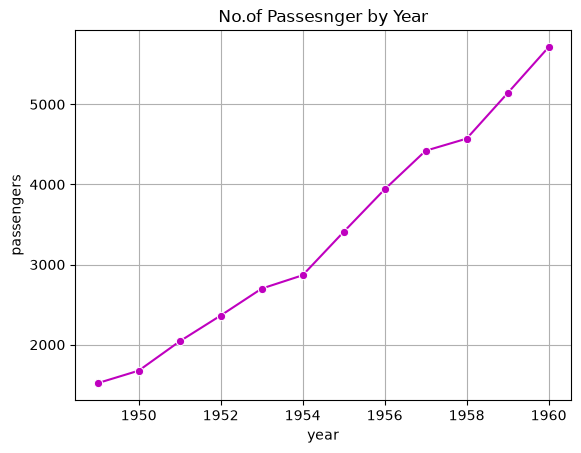

In [51]:
sb.lineplot( x = 'year', y = 'passengers', data = Year_Wise_Data, marker = 'o', color = 'm' )

plt.title("No.of Passesnger by Year")
plt.grid()

plt.show()

In [54]:
X = sb.load_dataset("tips")
X

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


# Scatter Plot  :  sb.scatterplot()

Text(0.5, 1.0, 'Total Bill vs Tip')

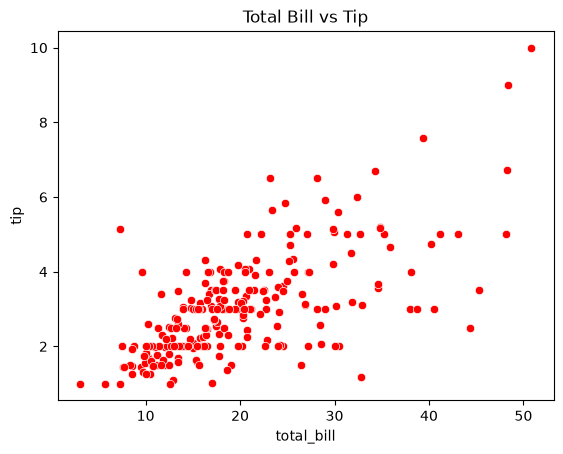

In [60]:
# Let's find relation between Total_bill and Tip

sb.scatterplot(data = X, x = 'total_bill', y = 'tip', color = 'r')

plt.title("Total Bill vs Tip")

<Axes: xlabel='total_bill', ylabel='tip'>

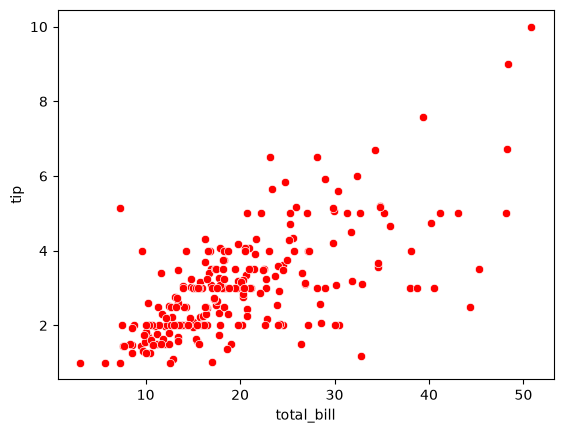

In [65]:
sb.scatterplot(data = X, x = 'total_bill', y = 'tip', color = 'r', markers = False)

# Pairplot : sb.pairplot()

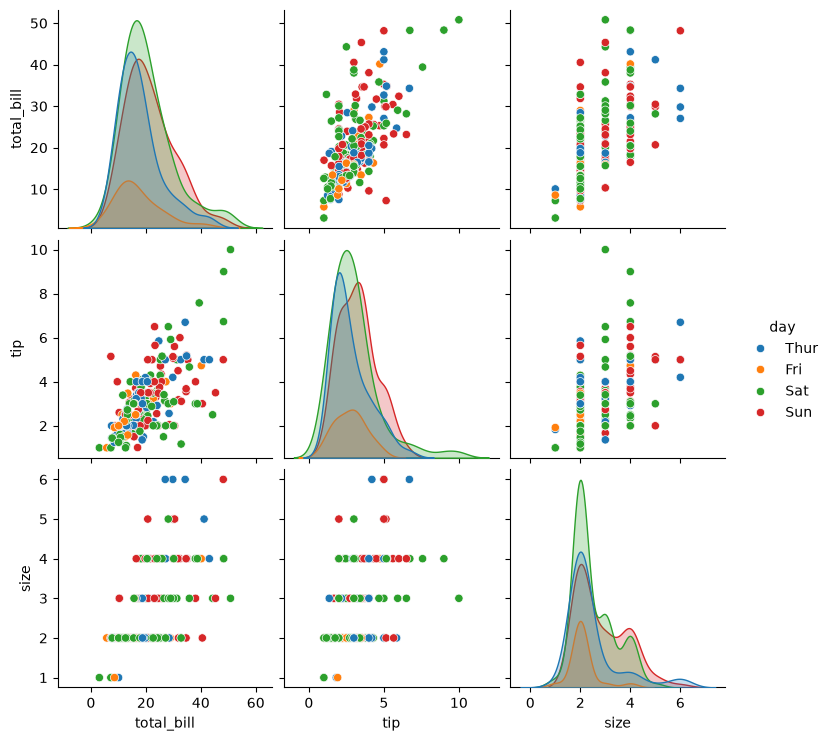

In [78]:
sb.pairplot(X, hue = 'day')      # hue  : Further Categorise the Data

plt.show()

# Day-02 (26-11-2026)

In [1]:
import seaborn as sb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Heatmap

In [3]:
Data = sb.load_dataset("tips")
Data

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [20]:
# .corr()  :  Used for showing Correlation between Numeric Variables.     ( Pandas)

Correlation = Data.corr(numeric_only = True)       # numeric_only = True --> Selecting only Numeric Columns.
Correlation

# correlation between 'total_bill' and 'tip' --> 0.675 => 67.5%

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


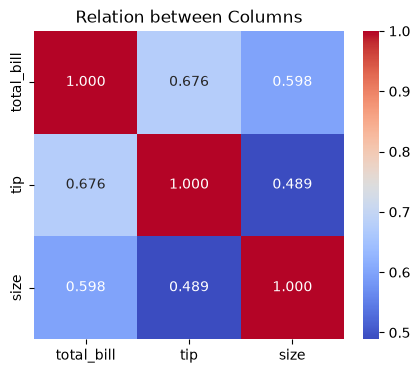

In [19]:
# Heatmap can help us to visualize the correlation matrix in better way

plt.figure(figsize = (5,4))
sb.heatmap(Correlation, annot = True, fmt = ".3f", cmap = 'coolwarm')      

# annot = True --> Shows the Data in the Cells
# fmt --> To Give desired no.of decimal places
# cmap --> To Customise Colors

plt.title("Relation between Columns")

plt.show()

# Heatmap is a Colorful representation of Correlation Matrix.

## Correlation between Categorical Variables

In [24]:
# pivot_table()  :  Used for Finnding the Correlation between Categorical Variables

# Q --> Which Gender is Smoking more ?

Pivot = Data.pivot_table( index = "day", columns = "smoker", aggfunc = "size" )

# index --> Row Categories
# aggfunc = 'size' --> Counting Particular Category

Pivot

smoker,Yes,No
day,,
Thur,17,45
Fri,15,4
Sat,42,45
Sun,19,57


In [22]:
Pivot_2 = Data.pivot_table( index = "sex", columns = "smoker", aggfunc = "size" )
Pivot_2

smoker,Yes,No
sex,,
Male,60,97
Female,33,54


<Axes: xlabel='smoker', ylabel='day'>

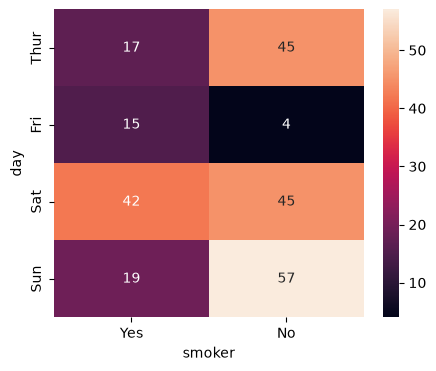

In [31]:
plt.figure(figsize = (5,4))
sb.heatmap(Pivot, annot = True)

In [32]:
# Pivot Table with Multiple indeex values

Pivot_3 = Data.pivot_table( index = ["day","sex"], columns = ["time","smoker"], aggfunc = "size")
Pivot_3

time        Lunch       Dinner      
smoker        Yes    No    Yes    No
day  sex                            
Thur Male    10.0  20.0    NaN   NaN
     Female   7.0  24.0    NaN   1.0
Fri  Male     3.0   NaN    5.0   2.0
     Female   3.0   1.0    4.0   1.0
Sat  Male     NaN   NaN   27.0  32.0
     Female   NaN   NaN   15.0  13.0
Sun  Male     NaN   NaN   15.0  43.0
     Female   NaN   NaN    4.0  14.0

<Axes: xlabel='time-smoker', ylabel='day-sex'>

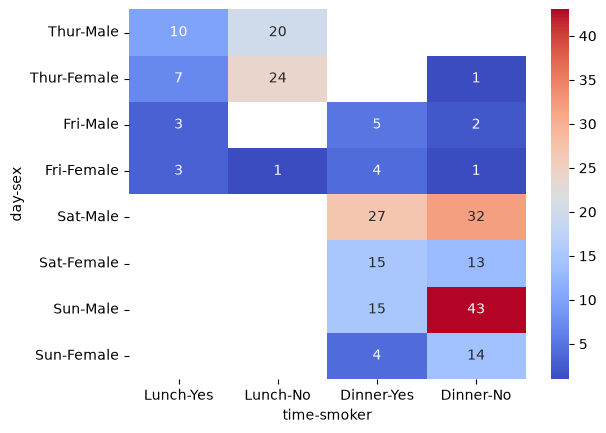

In [34]:
sb.heatmap(Pivot_3, annot = True, cmap = "coolwarm")

# Countplot()

<Axes: xlabel='day', ylabel='count'>

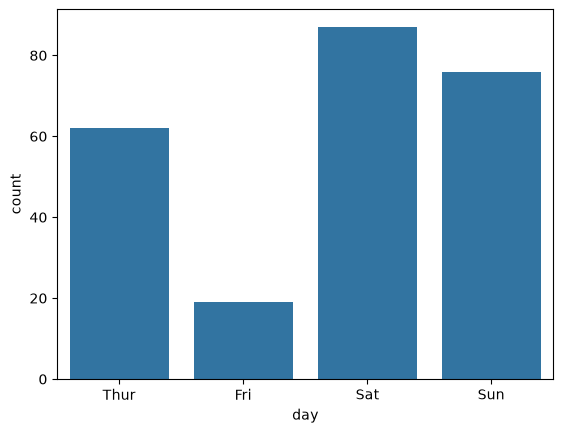

In [35]:
sb. countplot( data = Data, x = "day")

<Axes: xlabel='day', ylabel='count'>

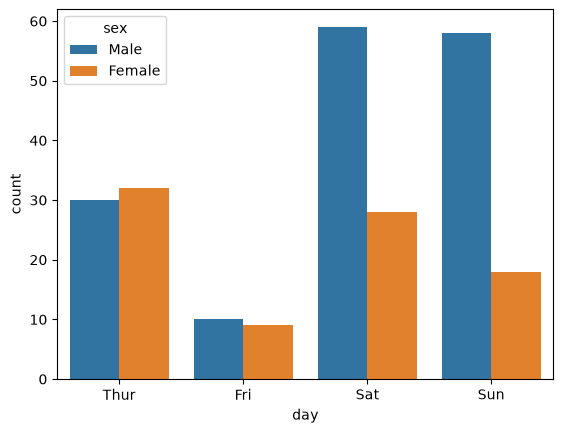

In [37]:
sb.countplot( data = Data, x = "day", hue = "sex")

# hue --> further categorize the data based upon Male/Female

# Boxplot

<Axes: ylabel='tip'>

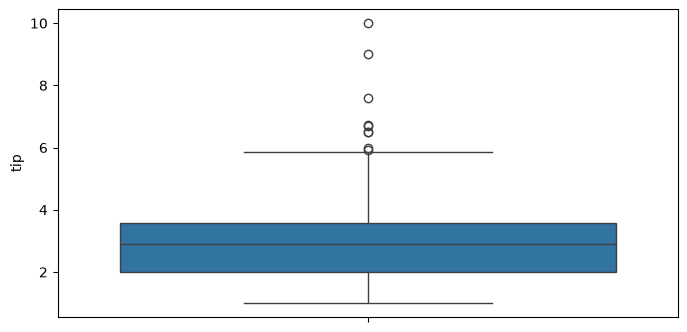

In [40]:
plt.figure(figsize = (8,4))
sb.boxplot( y = "tip", data = Data)      # x -> Horizontal, y -> Vertical

# IQR --> Inter Quantile Range = Q3 - Q1
# upper bound, Lower bound, Quantile's

<Axes: xlabel='day', ylabel='tip'>

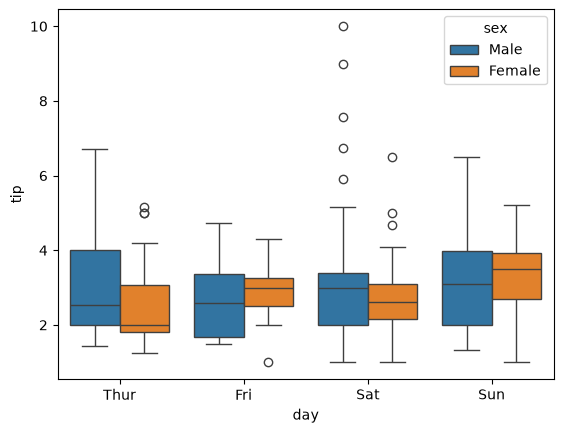

In [42]:
# Day-wise Outliers 

sb.boxplot( x = "day", y = "tip", data = Data, hue = "sex") 

<Axes: xlabel='day', ylabel='tip'>

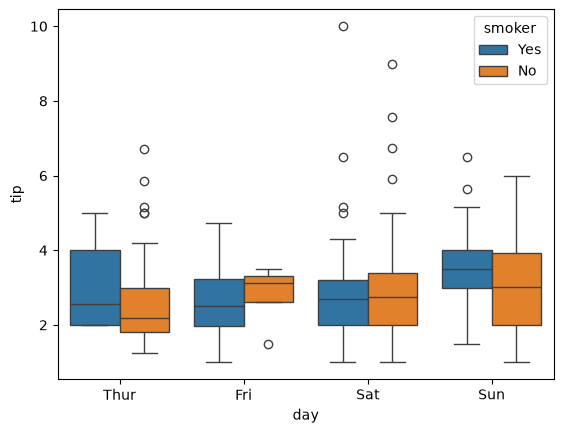

In [43]:
sb.boxplot( x = "day", y = "tip", data = Data, hue = "smoker") 

# Day-03 (27-11-2026)

In [1]:
import seaborn as sb
import matplotlib.pyplot as plt

In [34]:
Data = sb.load_dataset("tips")
Data

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


# Density Plot (KDE Plot)

<Axes: xlabel='total_bill', ylabel='Density'>

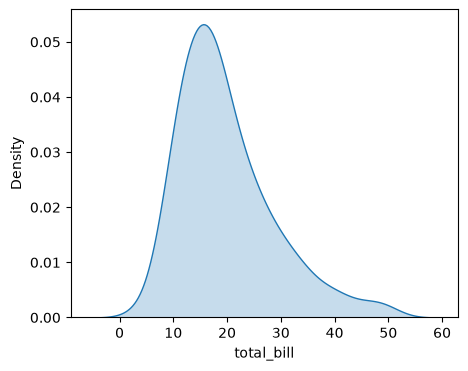

In [4]:
plt.figure(figsize = (5,4))
sb.kdeplot( data = Data, x = 'total_bill', fill = True)

<Axes: xlabel='total_bill', ylabel='Density'>

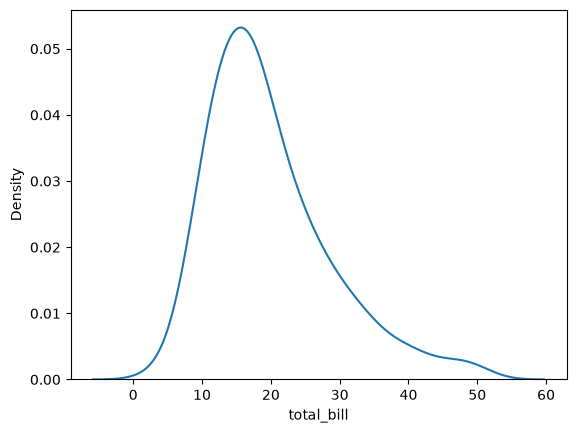

In [35]:
sb.kdeplot( data = Data, x = 'total_bill') #, fill = True)

# Viloin Chart

<Axes: ylabel='tip'>

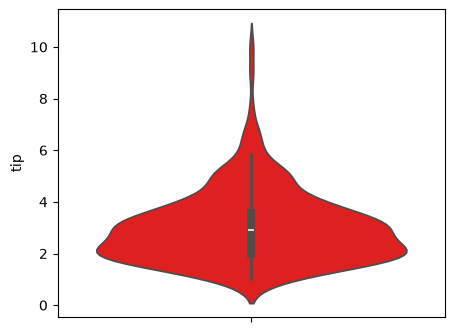

In [15]:
plt.figure(figsize = (5,4))
sb.violinplot( y = "tip", data = Data, color = 'r' )

<Axes: xlabel='sex', ylabel='tip'>

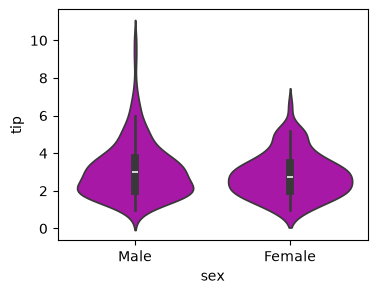

In [21]:
plt.figure(figsize = (4,3))
sb.violinplot( x = "sex", y = "tip", data = Data, color = 'm' )

# Regression Plot

<Axes: xlabel='total_bill', ylabel='tip'>

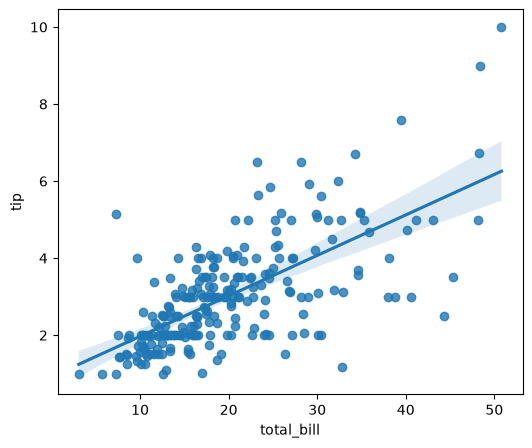

In [23]:
plt.figure(figsize = (6,5))
sb.regplot( x = "total_bill", y = "tip", data = Data )

# Facetgrid

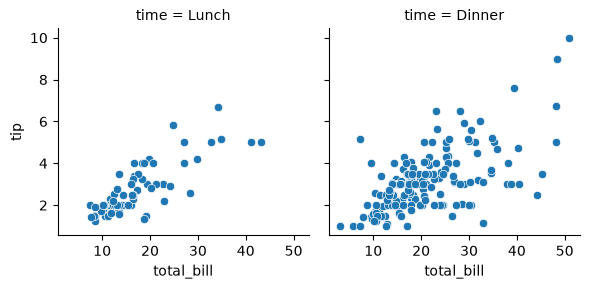

In [31]:
Fig = sb.FacetGrid( Data, col = "time" )
Fig.map_dataframe( sb.scatterplot, x = 'total_bill', y = 'tip')

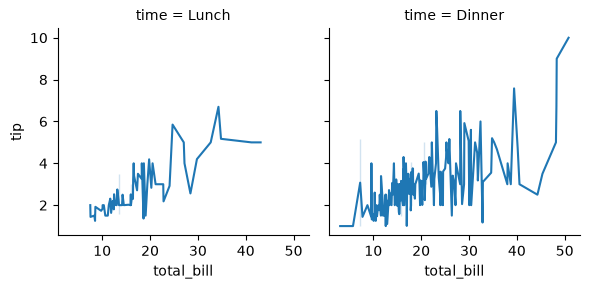

In [32]:
Fig = sb.FacetGrid( Data, col = "time" )
Fig.map_dataframe( sb.lineplot, x = 'total_bill', y = 'tip')

# Jointplot

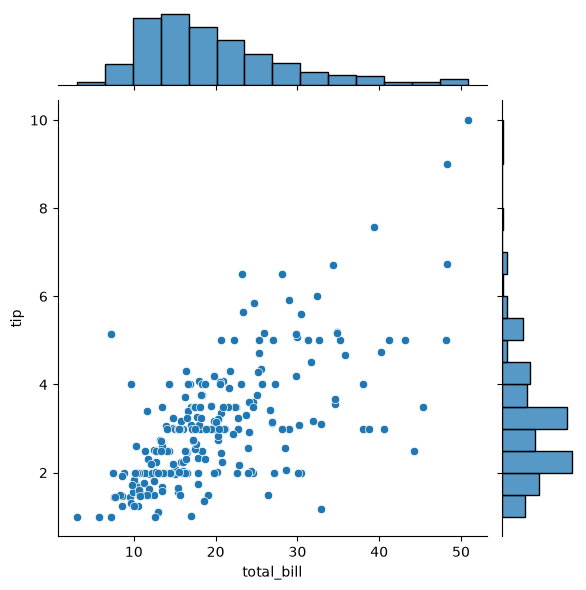

In [33]:
sb.jointplot( data = Data, x = 'total_bill', y = 'tip', kind = 'scatter' )